# Rent Prediction for KL & Selangor Apartments (6001CMD)

## A. Problem Definition
Predict `monthly_rent` (RM per month) of apartment listings in Kuala Lumpur and Selangor from the listing details (size, rooms, location, furnishing, facilities). This is supervised regression and the business metric is **MAE in RM**; RMSE and R² are reported as well.
Data: Kaggle "Rent Pricing Kuala Lumpur Malaysia" (ariewijaya), scraped from mudah.my. The code lives in `src/rental.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import StackingRegressor, VotingRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score, train_test_split

sys.path.insert(0, 'src')
from rental import (BASE_MODELS, CAT, CV, NUM, SCORING, build_preprocessor, evaluate,
                    load_and_clean, make_model, parse, tune)

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)
plt.rcParams.update({'savefig.dpi': 150, 'savefig.bbox': 'tight'})
for folder in ['figures', 'results', 'data/processed']:
    Path(folder).mkdir(parents=True, exist_ok=True)

RAW = 'data/raw/mudah-apartment-kl-selangor.csv'
BLUE = "steelblue"

## B. Exploratory Data Analysis
First the raw data, with only rent, size and rooms parsed into numbers.

In [2]:
orig = pd.read_csv(RAW)   # untouched raw columns
raw = parse(orig)         # rent, size and rooms as numbers, nothing removed
print('Rows, columns:', raw.shape)
print('Exact duplicate listings in the raw data (ignoring ads_id):', raw.drop(columns='ads_id').duplicated().sum())

pd.DataFrame({'dtype': orig.dtypes.astype(str), 'n_unique': orig.nunique(),
              'example': orig.apply(lambda c: c.dropna().iloc[0])}).rename_axis('column')

Rows, columns: (19991, 14)
Exact duplicate listings in the raw data (ignoring ads_id): 1541


,dtype,n_unique,example
column,,,
ads_id,int64,19978,100323185
prop_name,object,2826,The Hipster @ Taman Desa
completion_year,float64,42,2022.0
monthly_rent,object,387,RM 4 200 per month
location,object,134,Kuala Lumpur - Taman Desa
property_type,object,13,Condominium
rooms,object,18,5
parking,float64,9,2.0
bathroom,float64,8,6.0


In [3]:
num_cols = ['monthly_rent', 'size_sqft', 'rooms', 'bathroom', 'parking', 'completion_year']
stats = raw[num_cols].describe().T.assign(skew=raw[num_cols].skew()).round(2)
stats.to_csv('results/descriptive_stats.csv')
stats

,count,mean,std,min,25%,50%,75%,max,skew
monthly_rent,19989.0,2269.08,22412.85,70.0,1100.0,1400.0,1800.0,2400000.0,70.17
size_sqft,19991.0,5922.17,707259.59,1.0,750.0,886.0,1044.0,99999999.0,141.39
rooms,19983.0,2.68,0.81,1.0,2.0,3.0,3.0,10.0,-0.50
bathroom,19985.0,1.89,0.56,1.0,2.0,2.0,2.0,8.0,1.20
parking,14289.0,1.42,0.57,1.0,1.0,1.0,2.0,10.0,2.46
completion_year,10806.0,2014.82,6.74,1977.0,2012.0,2017.0,2020.0,2025.0,-1.40


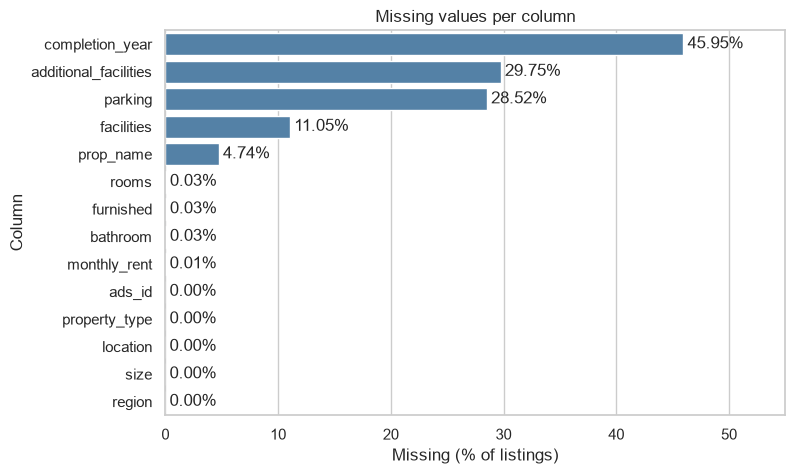

In [4]:
missing = (orig.isna().mean() * 100).round(2).sort_values(ascending=False).rename('missing_pct').rename_axis('column')
missing.to_csv('results/missing.csv')

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=missing.values, y=missing.index, color=BLUE, ax=ax)
ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=3)
ax.set(title='Missing values per column', xlabel='Missing (% of listings)', ylabel='Column', xlim=(0, 55))
plt.savefig('figures/fig_missing.png')
plt.show()

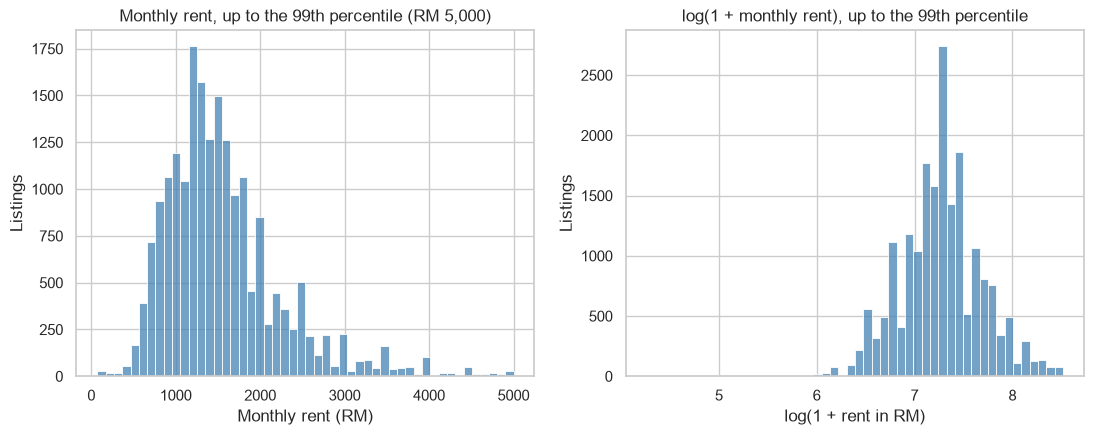

In [5]:
rent = raw['monthly_rent'].dropna()
cap = rent.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(rent[rent <= cap], bins=50, color=BLUE, ax=axes[0])
axes[0].set(title=f'Monthly rent, up to the 99th percentile (RM {cap:,.0f})', xlabel='Monthly rent (RM)', ylabel='Listings')
sns.histplot(np.log1p(rent[rent <= cap]), bins=50, color=BLUE, ax=axes[1])
axes[1].set(title='log(1 + monthly rent), up to the 99th percentile', xlabel='log(1 + rent in RM)', ylabel='Listings')
plt.savefig('figures/fig_rent_distribution.png')
plt.show()

Rent is strongly right-skewed (a few listings far above RM 10,000, up to RM 2.4 million), the log scale is much closer to symmetric. This is why the models train on `log1p(rent)`.

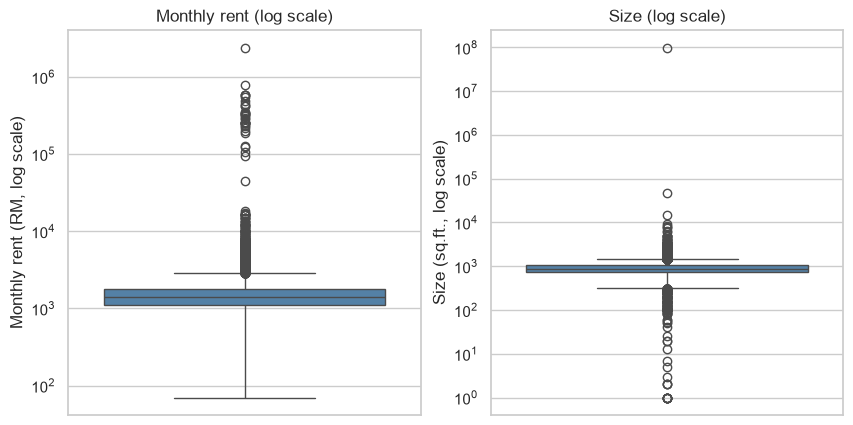

,variable,iqr_outliers,outside_domain_range,domain_range,min,max
0,monthly_rent,1269,116,"300 - 10,000",70.0,2400000.0
1,size_sqft,955,103,"200 - 5,000",1.0,99999999.0


In [6]:
# IQR rule vs the domain range used for cleaning (rent RM 300-10,000, size 200-5,000 sq.ft.)
rows = []
for col, low, high in [('monthly_rent', 300, 10_000), ('size_sqft', 200, 5_000)]:
    v = raw[col].dropna()
    q1, q3 = v.quantile([0.25, 0.75])
    fence = 1.5 * (q3 - q1)
    rows.append({'variable': col, 'iqr_outliers': int(((v < q1 - fence) | (v > q3 + fence)).sum()),
                 'outside_domain_range': int(((v < low) | (v > high)).sum()),
                 'domain_range': f'{low:,} - {high:,}', 'min': v.min(), 'max': v.max()})
outliers = pd.DataFrame(rows)
outliers.to_csv('results/outliers.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
sns.boxplot(y=raw['monthly_rent'], color=BLUE, ax=axes[0])
axes[0].set(title='Monthly rent (log scale)', ylabel='Monthly rent (RM, log scale)', yscale='log')
sns.boxplot(y=raw['size_sqft'], color=BLUE, ax=axes[1])
axes[1].set(title='Size (log scale)', ylabel='Size (sq.ft., log scale)', yscale='log')
plt.savefig('figures/fig_outliers_boxplot.png')
plt.show()
outliers

The IQR rule flags many genuine expensive or large units, so rows are removed with a domain range instead: rent RM 300-10,000 and size 200-5,000 sq.ft. (typos such as a size of 1 sq.ft. or a rent of RM 2.4 million fall outside).

The remaining EDA uses the cleaned data (`load_and_clean`, explained in section C).

In [7]:
df, log = load_and_clean(RAW)
fac_cols = [c for c in df if c.startswith('f_')]
df[CAT].describe().T

,count,unique,top,freq
property_type,17615,8,Condominium,7301
furnished,17615,3,Fully Furnished,7389
area,17615,125,Cheras,1883
region,17615,2,Selangor,8855


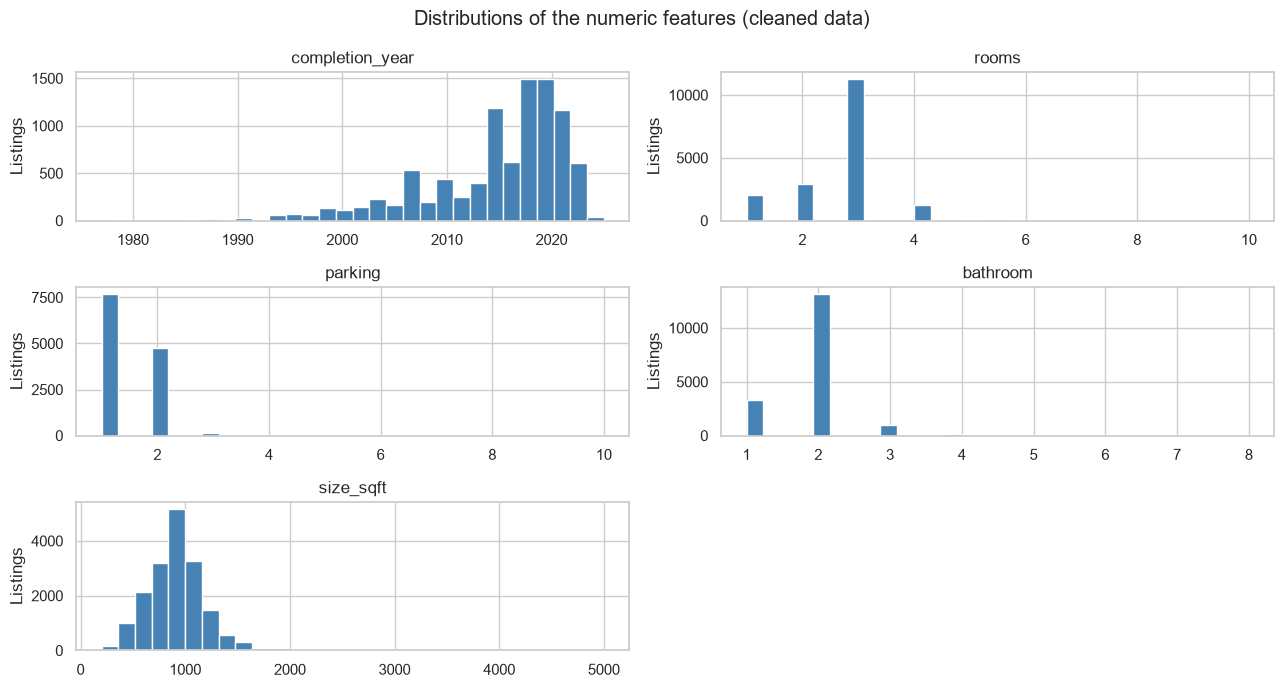

In [8]:
axes = df[NUM].hist(bins=30, figsize=(13, 7), color=BLUE)
for ax in axes.flat:
    ax.set_ylabel('Listings')
plt.suptitle('Distributions of the numeric features (cleaned data)')
plt.tight_layout()
plt.savefig('figures/fig_numeric_distributions.png')
plt.show()

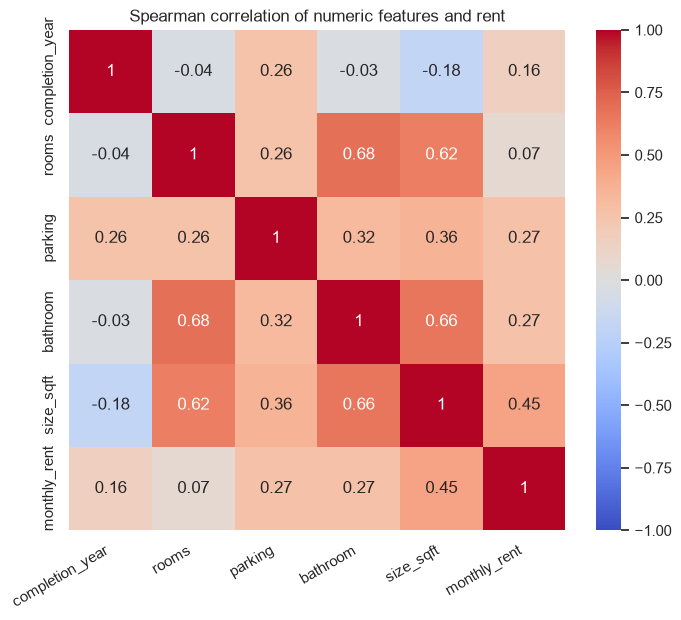

In [9]:
corr = df[NUM + ['monthly_rent']].corr(method='spearman').round(2)   # Spearman because rent and size are skewed
corr.to_csv('results/correlation.csv')

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 12}, ax=ax)
ax.set_title('Spearman correlation of numeric features and rent')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.savefig('figures/fig_correlation.png')
plt.show()

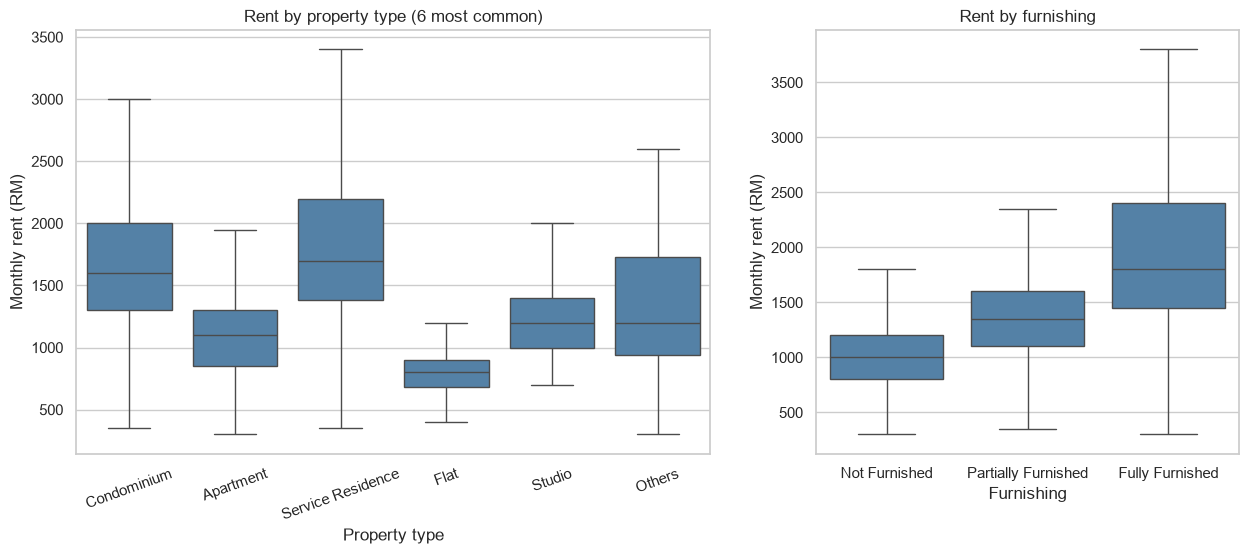

In [10]:
top_types = df['property_type'].value_counts().index[:6]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [3, 2]})
sns.boxplot(data=df[df['property_type'].isin(top_types)], x='property_type', y='monthly_rent', order=top_types,
            showfliers=False, color=BLUE, ax=axes[0])
axes[0].set(title='Rent by property type (6 most common)', xlabel='Property type', ylabel='Monthly rent (RM)')
axes[0].tick_params(axis='x', rotation=20)
sns.boxplot(data=df, x='furnished', y='monthly_rent', order=['Not Furnished', 'Partially Furnished', 'Fully Furnished'],
            showfliers=False, color=BLUE, ax=axes[1])
axes[1].set(title='Rent by furnishing', xlabel='Furnishing', ylabel='Monthly rent (RM)')
plt.savefig('figures/fig_rent_by_category.png')
plt.show()

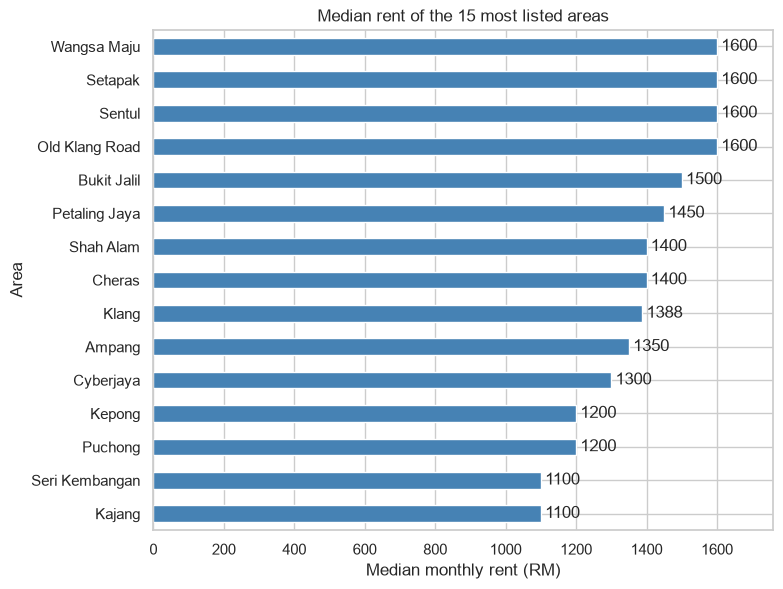

In [11]:
top_areas = df['area'].value_counts().index[:15]
area_median = df[df['area'].isin(top_areas)].groupby('area')['monthly_rent'].median().sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
area_median.plot.barh(color=BLUE, ax=ax)
ax.bar_label(ax.containers[0], fmt='%.0f', padding=3)
ax.set(title='Median rent of the 15 most listed areas', xlabel='Median monthly rent (RM)', ylabel='Area', xlim=(0, area_median.max() * 1.1))
plt.savefig('figures/fig_rent_by_area.png')
plt.show()

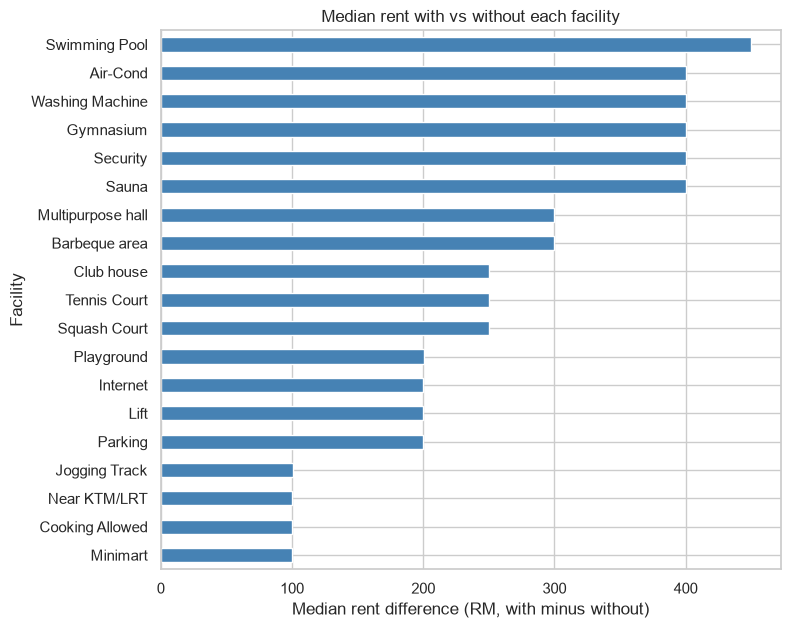

In [12]:
effect = pd.Series({f.removeprefix('f_'): df.groupby(f)['monthly_rent'].median().diff().iloc[-1] for f in fac_cols}).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
effect.plot.barh(color=BLUE, ax=ax)
ax.set(title='Median rent with vs without each facility', xlabel='Median rent difference (RM, with minus without)', ylabel='Facility')
plt.savefig('figures/fig_facilities.png')
plt.show()

Facilities are correlated with the property itself (a listing with a gym and sauna is usually a bigger condominium), so these are associations, not the effect of adding a facility.

## C. Data Preparation
`load_and_clean` parses the text columns, applies the domain range rule, drops missing rent/rooms, adds the 19 facility flags and finally drops rows that are duplicated on the modelled columns (reposts and identical twin listings). This happens before the split, so the same listing cannot land in both train and test. Missing `completion_year` and `parking` are imputed inside the model pipeline.

In [13]:
cleaning = pd.Series(log, name='rows').rename_axis('step').to_frame()
cleaning['removed'] = (cleaning['rows'].shift() - cleaning['rows']).fillna(0).astype(int)
cleaning.to_csv('results/cleaning_log.csv')
df.to_csv('data/processed/rent_clean.csv', index=False)

X, y = df.drop(columns='monthly_rent'), df['monthly_rent']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape, ' Facility flags:', len(fac_cols))
print(f'{X_train.shape[1]} input columns -> {build_preprocessor().fit_transform(X_train).shape[1]} features after preprocessing')
cleaning

Train: (14092, 28)  Test: (3523, 28)  Facility flags: 19


28 input columns -> 119 features after preprocessing


,rows,removed
step,,
raw,19991,0
after_range_filter,19799,192
after_missing_rooms,19795,4
after_duplicates,17615,2180


In [14]:
# The same data as the models see it: blanks filled, "was missing" flags added, text one-hot encoded, numbers scaled.
# Fitted on the training rows only, then applied to all rows. Rent stays in RM; the log is applied inside the model.
prep = build_preprocessor().fit(X_train)
ready = pd.DataFrame(prep.transform(X), columns=prep.get_feature_names_out()).round(4)
ready['monthly_rent'] = y
ready['split'] = np.where(X.index.isin(X_train.index), 'train', 'test')
ready.to_csv('data/processed/rent_model_ready.csv', index=False)
print('Model-ready table:', ready.shape)
ready.head()

Model-ready table: (17615, 121)


,num__completion_year,num__rooms,num__parking,num__bathroom,num__size_sqft,num__missingindicator_completion_year,num__missingindicator_parking,cat__property_type_Apartment,cat__property_type_Condominium,cat__property_type_Duplex,...,remainder__f_Squash Court,remainder__f_Swimming Pool,remainder__f_Tennis Court,remainder__f_Air-Cond,remainder__f_Cooking Allowed,remainder__f_Internet,remainder__f_Near KTM/LRT,remainder__f_Washing Machine,monthly_rent,split
0,1.2182,2.8780,1.3957,7.4028,2.9910,-0.9245,-0.6280,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,4200.0,train
1,0.2411,0.3894,-0.5824,0.1895,0.8107,1.0817,-0.6280,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,2300.0,train
2,0.2411,0.3894,-0.5824,0.1895,-0.8764,1.0817,1.5923,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1000.0,train
3,0.8273,-0.8549,-0.5824,0.1895,-0.5746,-0.9245,-0.6280,1.0,0.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1700.0,test
4,0.2411,-2.0992,-0.5824,-1.6138,-1.3825,1.0817,-0.6280,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1299.0,train


### Preprocessing ablation
The three base models at default settings under the same 5-fold CV on the training set, removing one preprocessing choice at a time. A dummy model that always predicts the median rent is the baseline.

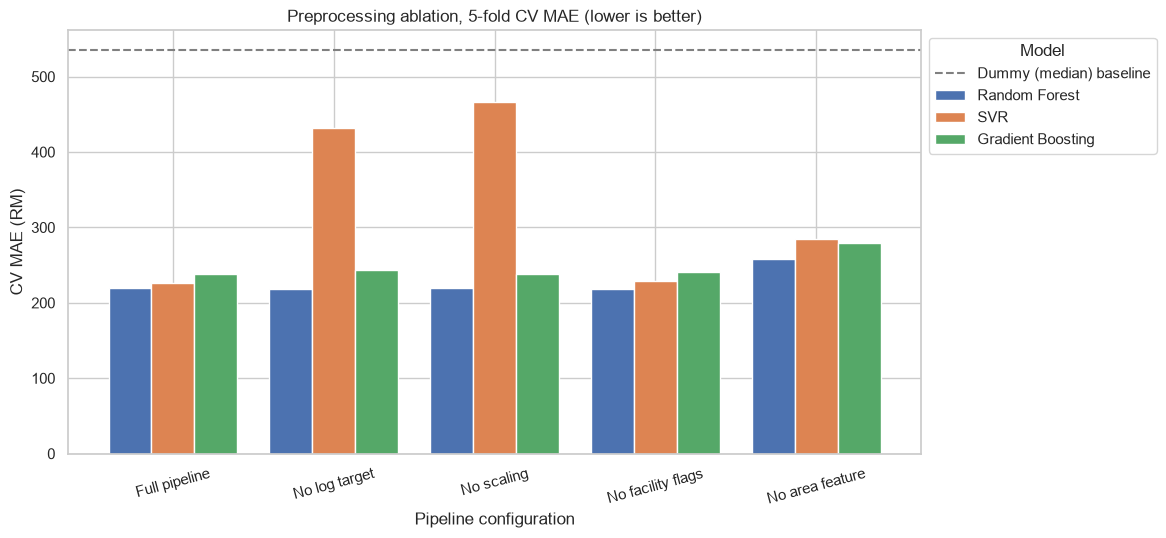

,Random Forest,SVR,Gradient Boosting
config,,,
Full pipeline,219.42,225.75,237.58
No log target,217.88,431.20,243.34
No scaling,219.46,466.16,237.58
No facility flags,217.97,229.23,240.43
No area feature,257.98,284.06,278.66
Dummy (median),534.89,534.89,534.89


In [15]:
configs = {'Full pipeline': (X_train, {}),
           'No log target': (X_train, {'log_target': False}),
           'No scaling': (X_train, {'scale': False}),
           'No facility flags': (X_train[NUM + CAT], {}),
           'No area feature': (X_train.drop(columns='area'), {})}

ablation = pd.DataFrame(index=pd.Index(list(configs), name='config'), columns=list(BASE_MODELS), dtype=float)
for config, (data, options) in configs.items():
    for name, (estimator, _, _) in BASE_MODELS.items():
        scores = cross_val_score(make_model(estimator, **options), data, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
        ablation.loc[config, name] = -scores.mean()

dummy_cv = -cross_val_score(DummyRegressor(strategy='median'), X_train, y_train, cv=CV, scoring=SCORING)
ablation.loc['Dummy (median)'] = dummy_cv.mean()
ablation = ablation.round(2)
ablation.to_csv('results/ablation.csv')

ax = ablation.iloc[:-1].plot.bar(figsize=(11, 5.5), rot=15, width=0.8)
ax.axhline(ablation.loc['Dummy (median)'].iloc[0], color='grey', ls='--', label='Dummy (median) baseline')
ax.set(title='Preprocessing ablation, 5-fold CV MAE (lower is better)', xlabel='Pipeline configuration', ylabel='CV MAE (RM)')
ax.legend(title='Model', loc='upper left', bbox_to_anchor=(1, 1))
plt.savefig('figures/fig_ablation.png')
plt.show()
ablation

### Extra preprocessing checks (report Table 6, added rows)
Alternatives to single steps: no missing-value indicator, no rare-area grouping, complete cases only, Yeo-Johnson / Box-Cox target instead of log, and duplicates kept (to show the leakage).

In [ ]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

def variant_model(estimator, indicator=True, min_frequency=20, target='log'):
    """Same pipeline as make_model, with one choice switched."""
    num = make_pipeline(SimpleImputer(strategy='median', add_indicator=indicator), StandardScaler())
    onehot = OneHotEncoder(handle_unknown='infrequent_if_exist' if min_frequency else 'ignore',
                           min_frequency=min_frequency, sparse_output=False)
    prep = ColumnTransformer([('num', num, NUM), ('cat', onehot, make_column_selector(dtype_include=object))],
                             remainder='passthrough')
    pipe = Pipeline([('prep', prep), ('model', estimator)])
    if target == 'log':
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return TransformedTargetRegressor(regressor=pipe, transformer=PowerTransformer(method=target))

# duplicates kept: the same cleaning as load_and_clean, without drop_duplicates
d = raw[raw['monthly_rent'].between(300, 10_000) & raw['size_sqft'].between(200, 5_000)].dropna(subset=['monthly_rent', 'rooms'])
d = d.assign(area=d['location'].str.split(' - ').str[1])
flags = pd.concat([d[c].fillna('').str.get_dummies(sep=', ') for c in ['facilities', 'additional_facilities']], axis=1)
flags = flags.loc[:, ~flags.columns.str.fullmatch(r'\d*')].add_prefix('f_')
d = pd.concat([d, flags], axis=1)[['monthly_rent'] + NUM + CAT + list(flags.columns)].reset_index(drop=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(d.drop(columns='monthly_rent'), d['monthly_rent'], test_size=0.2, random_state=42)
train_keys = set(map(tuple, pd.concat([yd_train, Xd_train], axis=1).astype(str).values))
copies = sum(tuple(r) in train_keys for r in pd.concat([yd_test, Xd_test], axis=1).astype(str).values)
print(f'With duplicates kept, {copies} of {len(Xd_test)} test listings have an exact copy in the training set')

complete = X_train[['completion_year', 'parking']].notna().all(axis=1)
print('Complete-case training rows:', complete.sum(), 'of', len(X_train))
print('Rent skewness: raw %.2f, log1p %.2f, Yeo-Johnson %.2f' % (y_train.skew(), np.log1p(y_train).skew(),
      pd.Series(PowerTransformer('yeo-johnson').fit_transform(y_train.to_frame()).ravel()).skew()))

variants = {'No missing indicator': (X_train, y_train, {'indicator': False}),
            'No rare-area grouping': (X_train, y_train, {'min_frequency': None}),
            'Complete cases only': (X_train[complete], y_train[complete], {}),
            'Yeo-Johnson target (not log)': (X_train, y_train, {'target': 'yeo-johnson'}),
            'Box-Cox target (not log)': (X_train, y_train, {'target': 'box-cox'}),
            'Duplicates kept': (Xd_train, yd_train, {})}
extra = pd.DataFrame(index=pd.Index(list(variants), name='config'), columns=list(BASE_MODELS), dtype=float)
for config, (Xv, yv, options) in variants.items():
    for name, (estimator, _, _) in BASE_MODELS.items():
        extra.loc[config, name] = -cross_val_score(variant_model(estimator, **options), Xv, yv, cv=CV,
                                                   scoring=SCORING, n_jobs=-1).mean()
extra = extra.round(2)
extra.to_csv('results/ablation_extra.csv')
extra

## D. Base Models
Random Forest (bagged trees), SVR with an RBF kernel (needs the scaling) and histogram Gradient Boosting (boosted trees). All three are wrapped in the same preprocessing and log target.

In [16]:
for name, (estimator, space, search) in BASE_MODELS.items():
    print(f'{name} ({search} search): {estimator}\n    {space}')

Random Forest (random search): RandomForestRegressor(n_jobs=1, random_state=42)
    {'n_estimators': [100, 200, 400], 'max_depth': [None, 10, 20, 30], 'min_samples_leaf': [1, 2, 4], 'max_features': [1.0, 'sqrt', 0.5]}
SVR (grid search): SVR()
    {'C': [0.3, 1, 3, 10], 'gamma': ['scale', 0.01, 0.03], 'epsilon': [0.02, 0.05]}
Gradient Boosting (random search): HistGradientBoostingRegressor(random_state=42)
    {'learning_rate': [0.01, 0.03, 0.05, 0.1], 'max_iter': [500, 1000, 2000], 'max_leaf_nodes': [31, 63, 127], 'min_samples_leaf': [5, 10, 20, 50], 'l2_regularization': [0, 0.1, 1]}


## E. Hyperparameter Optimisation
Each model gets its default CV MAE and then a search (Random: 20 draws, SVR: full grid) on the same 5 folds of the training set.

Random Forest: CV MAE default 219.4 -> tuned 218.3 RM, search 260s


SVR: CV MAE default 225.8 -> tuned 220.6 RM, search 1290s


Gradient Boosting: CV MAE default 237.6 -> tuned 215.9 RM, search 393s


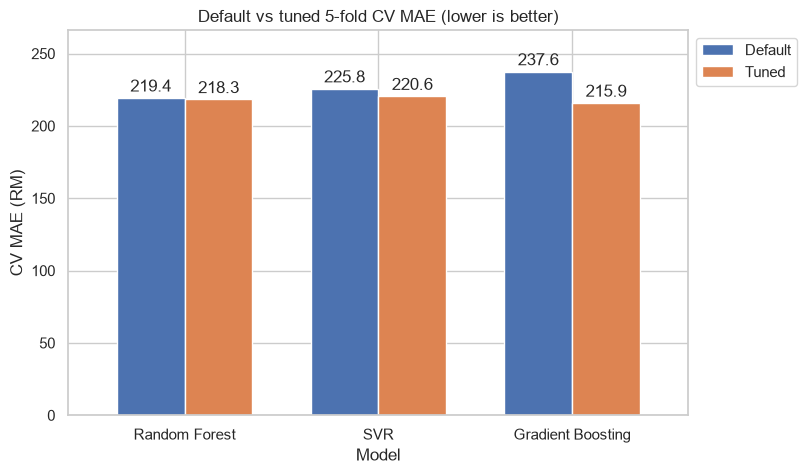

,default_cv_mae,tuned_cv_mae,tuned_cv_mae_std,improvement_pct,best_params,search_seconds
model,,,,,,
Random Forest,219.4235,218.3220,6.7413,0.5020,"{'n_estimators': 400, 'min_samples_leaf': 1, '...",260.2324
SVR,225.7544,220.5576,5.9896,2.3019,"{'C': 3, 'epsilon': 0.05, 'gamma': 0.03}",1290.2600
Gradient Boosting,237.5761,215.8697,5.6466,9.1366,"{'min_samples_leaf': 5, 'max_leaf_nodes': 127,...",392.8564


In [17]:
tuned, rows = {}, []
for name in BASE_MODELS:
    tuned[name], info = tune(name, X_train, y_train)
    rows.append(info)
    print(f"{name}: CV MAE default {info['default_cv_mae']:.1f} -> tuned {info['tuned_cv_mae']:.1f} RM, search {info['search_seconds']:.0f}s")

tuning = pd.DataFrame(rows).set_index('model')
tuning.round(4).to_csv('results/tuning.csv')

ax = tuning[['default_cv_mae', 'tuned_cv_mae']].plot.bar(figsize=(8, 5), rot=0, width=0.7)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', padding=2)
ax.set(title='Default vs tuned 5-fold CV MAE (lower is better)', xlabel='Model', ylabel='CV MAE (RM)',
       ylim=(0, tuning[['default_cv_mae', 'tuned_cv_mae']].max().max() * 1.12))
ax.legend(['Default', 'Tuned'], loc='upper left', bbox_to_anchor=(1, 1))
plt.savefig('figures/fig_tuning.png')
plt.show()
tuning.round(4)

## F. Ensemble
The two tuned base models with the lowest CV MAE are combined as equal-weight Voting and as Stacking (the default RidgeCV meta-model). The one with the lower 5-fold CV MAE on the training set is chosen, never by the test set.

In [18]:
top2 = tuning['tuned_cv_mae'].nsmallest(2).index   # the third model is left out
members = [(name, tuned[name]) for name in top2]
# StackingRegressor's default final estimator is RidgeCV
candidates = {'Voting': VotingRegressor(members), 'Stacking': StackingRegressor(members, cv=5)}

rows = []
for technique, model in candidates.items():
    scores = -cross_val_score(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    rows.append({'technique': technique, 'members': ' + '.join(top2), 'cv_mae': scores.mean(), 'cv_mae_std': scores.std()})

ens_compare = pd.DataFrame(rows)
winner = ens_compare['cv_mae'].idxmin()
ens_compare['chosen'] = ens_compare.index == winner
ens_compare.round(4).to_csv('results/ensemble_compare.csv', index=False)
ensemble = candidates[ens_compare.loc[winner, 'technique']]
ens_label = f"Ensemble ({ens_compare.loc[winner, 'technique']})"
print('Chosen ensemble:', ens_label, 'of', ' + '.join(top2))
ens_compare.round(4)

Chosen ensemble: Ensemble (Voting) of Gradient Boosting + Random Forest


,technique,members,cv_mae,cv_mae_std,chosen
0,Voting,Gradient Boosting + Random Forest,211.3597,6.0334,True
1,Stacking,Gradient Boosting + Random Forest,212.8406,5.5848,False


### Checking the other model pairs
The brief asks for the best two models, but SVR's errors are less correlated with the trees' errors. Every pair is scored as an equal-weight voting ensemble on the same folds.

In [ ]:
from itertools import combinations
pairs = []
for a, b in combinations(tuning['tuned_cv_mae'].sort_values().index, 2):
    scores = -cross_val_score(VotingRegressor([(a, tuned[a]), (b, tuned[b])]), X_train, y_train,
                              cv=CV, scoring=SCORING, n_jobs=-1)
    pairs.append({'pair': f'{a} + {b}', 'cv_mae': scores.mean(), 'cv_mae_std': scores.std()})
pairs = pd.DataFrame(pairs).round(2)
pairs.to_csv('results/ensemble_pairs.csv', index=False)
pairs

## G. Evaluation
Final test-set scores. Each model is refit on the full training set and scored once on the 20% test set.

In [19]:
models = {**tuned, ens_label: ensemble}
rows, preds = [], {}
for name, model in models.items():
    row, preds[name] = evaluate(name, model, X_train, y_train, X_test, y_test)
    rows.append(row)
row, preds['Dummy (median)'] = evaluate('Dummy (median)', DummyRegressor(strategy='median'), X_train, y_train, X_test, y_test)
rows.append(row)

test_metrics = pd.DataFrame(rows).set_index('model').round(4)
test_metrics.to_csv('results/test_metrics.csv')
test_metrics

,test_mae,test_mse,test_rmse,test_r2,train_mae,train_r2,fit_seconds,predict_seconds
model,,,,,,,,
Random Forest,206.5552,115485.8889,339.8321,0.8216,84.6777,0.9630,43.0863,0.3332
SVR,213.1856,113192.0166,336.4402,0.8252,156.1194,0.8939,25.9703,4.8403
Gradient Boosting,202.2144,106036.6448,325.6327,0.8362,117.2851,0.9484,9.2115,0.0636
Ensemble (Voting),199.2312,104589.2962,323.4027,0.8385,97.8394,0.9609,49.7367,0.3841
Dummy (median),536.7227,669895.3670,818.4714,-0.0346,534.8859,-0.0370,0.0006,0.0001


In [20]:
# Evidence for ensemble diversity: how correlated are the tuned models' test errors?
residuals = pd.DataFrame({name: y_test - preds[name] for name in tuned})
residual_corr = residuals.corr().round(3)
residual_corr.to_csv('results/residual_corr.csv')
residual_corr

,Random Forest,SVR,Gradient Boosting
Random Forest,1.000,0.817,0.888
SVR,0.817,1.000,0.851
Gradient Boosting,0.888,0.851,1.000


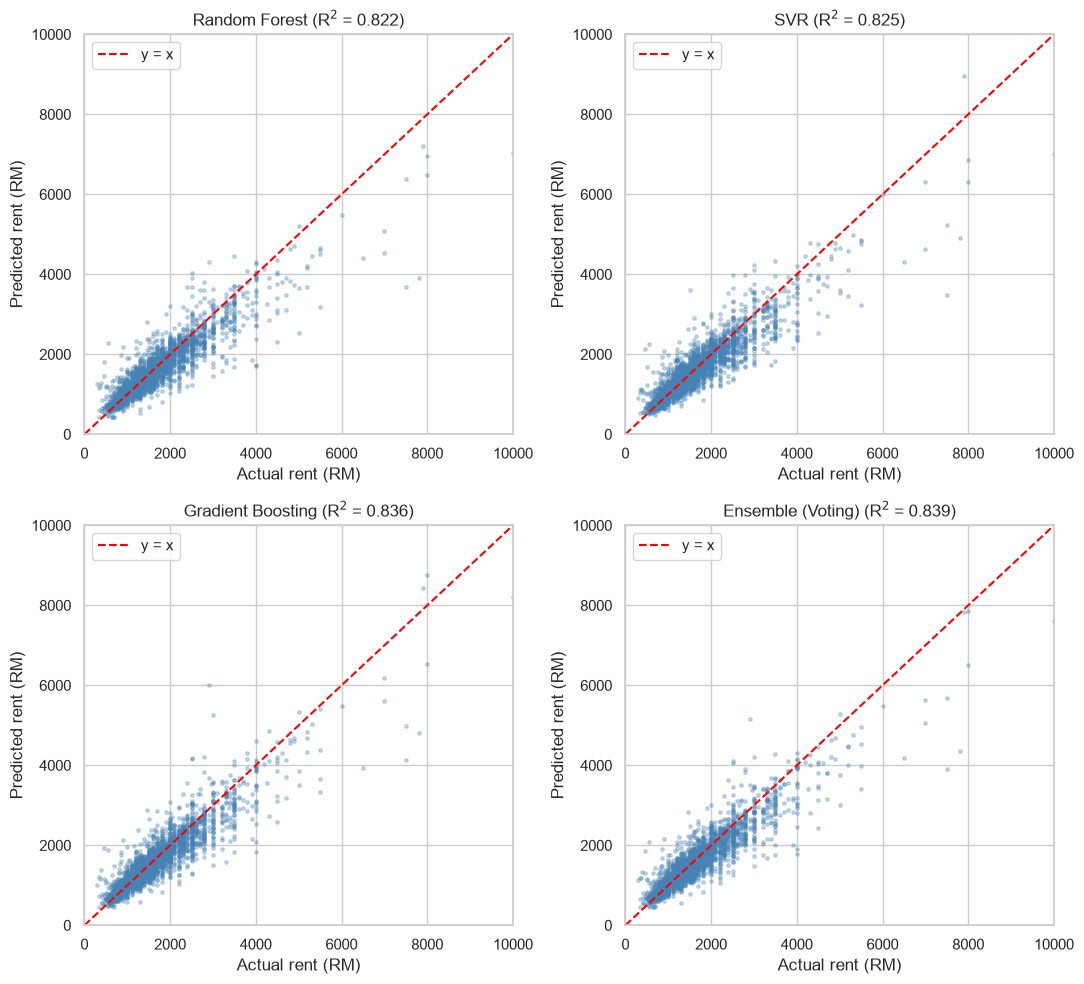

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, name in zip(axes.flat, models):
    ax.scatter(y_test, preds[name], s=6, alpha=0.3, color=BLUE)
    ax.plot([0, 10_000], [0, 10_000], color='red', ls='--', label='y = x')
    ax.set(xlim=(0, 10_000), ylim=(0, 10_000), title=f"{name} (R$^2$ = {test_metrics.loc[name, 'test_r2']:.3f})",
           xlabel='Actual rent (RM)', ylabel='Predicted rent (RM)')
    ax.legend()
plt.tight_layout()
plt.savefig('figures/fig_pred_vs_actual.png')
plt.show()

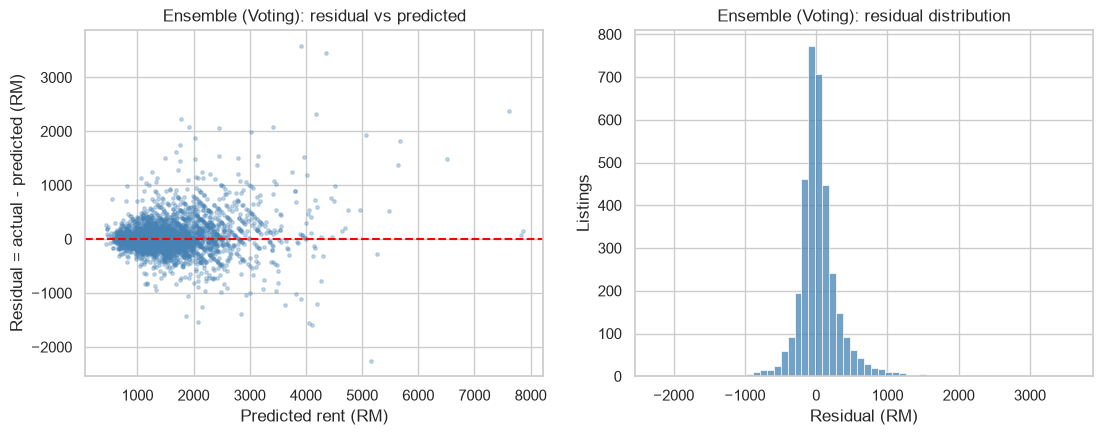

In [22]:
residual = y_test - preds[ens_label]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(preds[ens_label], residual, s=6, alpha=0.3, color=BLUE)
axes[0].axhline(0, color='red', ls='--')
axes[0].set(title=f'{ens_label}: residual vs predicted', xlabel='Predicted rent (RM)', ylabel='Residual = actual - predicted (RM)')
sns.histplot(residual, bins=60, color=BLUE, ax=axes[1])
axes[1].set(title=f'{ens_label}: residual distribution', xlabel='Residual (RM)', ylabel='Listings')
plt.savefig('figures/fig_residuals.png')
plt.show()

### Learning curves (report Figure 13)

In [ ]:
from sklearn.model_selection import learning_curve
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, (name, model) in zip(axes, tuned.items()):
    sizes, train_s, valid_s = learning_curve(model, X_train, y_train, train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
                                             cv=CV, scoring=SCORING, n_jobs=-1)
    ax.plot(sizes, -train_s.mean(1), 'o-', color=BLUE, label='Training MAE')
    ax.plot(sizes, -valid_s.mean(1), 's-', color='darkorange', label='Validation MAE (5-fold CV)')
    ax.set(title=name, xlabel='Training listings', ylabel='MAE (RM)' if ax is axes[0] else '')
axes[0].legend()
plt.tight_layout()
plt.savefig('figures/fig_learning_curves.png')
plt.show()

In [23]:
# Paired Wilcoxon test on per-listing absolute errors: chosen ensemble vs each tuned base model
error_ens = (y_test - preds[ens_label]).abs()
rows = []
for name in tuned:
    error_base = (y_test - preds[name]).abs()
    rows.append({'model_a': ens_label, 'model_b': name,
                 'mae_a': error_ens.mean(), 'mae_b': error_base.mean(), 'mae_diff': error_ens.mean() - error_base.mean(),
                 'median_abs_error_diff': (error_ens - error_base).median(),
                 'p_value': wilcoxon(error_ens, error_base).pvalue})
significance = pd.DataFrame(rows).round(4)
significance.to_csv('results/significance.csv', index=False)
significance

,model_a,model_b,mae_a,mae_b,mae_diff,median_abs_error_diff,p_value
0,Ensemble (Voting),Random Forest,199.2312,206.5552,-7.3240,-2.1217,0.0000
1,Ensemble (Voting),SVR,199.2312,213.1856,-13.9544,-10.7273,0.0000
2,Ensemble (Voting),Gradient Boosting,199.2312,202.2144,-2.9831,-3.2846,0.0001


### Scalability check
Fit time of each tuned model on growing training samples, to compare with the complexity in Section D.

In [ ]:
import time
from sklearn.base import clone
rows = []
for n in [2000, 4000, 8000, len(X_train)]:
    for name, model in tuned.items():
        start = time.perf_counter()
        clone(model).fit(X_train.iloc[:n], y_train.iloc[:n])
        rows.append({'n': n, 'model': name, 'fit_seconds': time.perf_counter() - start})
scaling = pd.DataFrame(rows).pivot(index='n', columns='model', values='fit_seconds').round(2)
scaling.to_csv('results/scaling.csv')
scaling

In [24]:
# Error of the chosen ensemble by rent band; within_20pct = share of listings with error <= 20% of the actual rent
labels = ['RM 300-999', 'RM 1,000-1,999', 'RM 2,000-3,999', 'RM 4,000-10,000']
errors = pd.DataFrame({'band': pd.cut(y_test, [300, 1000, 2000, 4000, 10_001], right=False, labels=labels).astype(str),
                       'abs_error': (y_test - preds[ens_label]).abs()})
errors['within_20pct'] = 100 * (errors['abs_error'] <= 0.2 * y_test)

by_band = (pd.concat([errors, errors.assign(band='All')]).groupby('band')
           .agg(n=('abs_error', 'size'), mae=('abs_error', 'mean'), within_20pct=('within_20pct', 'mean'))
           .reindex(labels + ['All']).round(4))
by_band.to_csv('results/error_by_band.csv')
by_band

,n,mae,within_20pct
band,,,
RM 300-999,623,130.0196,73.3547
"RM 1,000-1,999",2094,147.1483,86.4374
"RM 2,000-3,999",742,339.7926,77.6280
"RM 4,000-10,000",64,947.4166,59.3750
All,3523,199.2312,81.7769


### Error by area (report Table 12)
Areas with at least 30 test listings. Bias = mean(predicted - actual); negative means the area is under-priced.

In [ ]:
e = pd.DataFrame({'area': X_test['area'], 'actual': y_test, 'pred': preds[ens_label]})
e['abs_err'] = (e['actual'] - e['pred']).abs()
e['pct_err'] = 100 * e['abs_err'] / e['actual']
e['signed'] = e['pred'] - e['actual']
by_area = (e.groupby('area').agg(n=('abs_err', 'size'), median_rent=('actual', 'median'), mae=('abs_err', 'mean'),
                                 mape=('pct_err', 'mean'), bias=('signed', 'mean'))
           .query('n >= 30').round(1).sort_values('mape', ascending=False))
by_area.to_csv('results/error_by_area.csv')
print('Areas:', len(by_area), ' corr(median rent, bias):', round(by_area['median_rent'].corr(by_area['bias']), 2))
pd.concat([by_area.head(5), by_area.tail(5)])

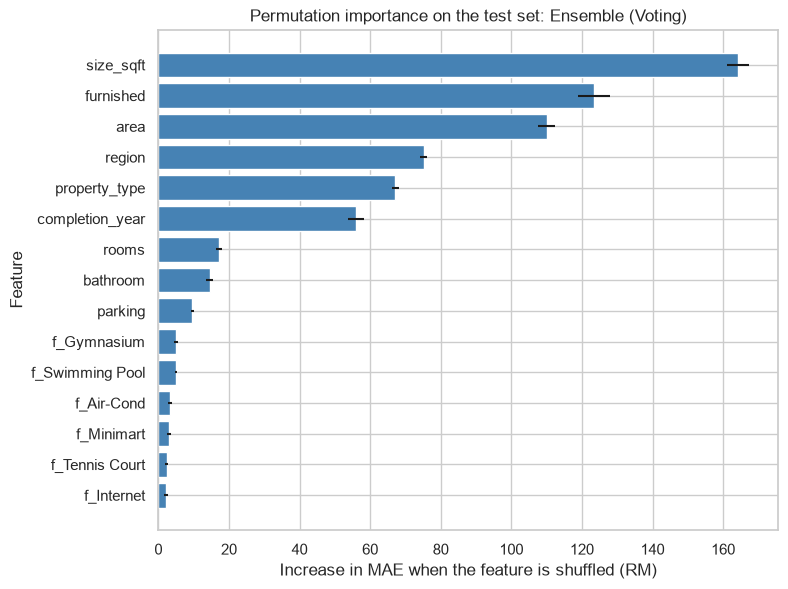

,feature,mae_increase_rm,std
4,size_sqft,164.1443,3.1538
6,furnished,123.4536,4.6218
7,area,110.0448,2.4262
8,region,75.1874,0.9859
5,property_type,67.0521,0.9984
0,completion_year,56.0357,2.1976
1,rooms,17.1814,0.7479
3,bathroom,14.5193,0.9554
2,parking,9.6473,0.3109
11,f_Gymnasium,4.9328,0.5502


In [25]:
imp = permutation_importance(ensemble, X_test, y_test, scoring=SCORING, n_repeats=5, random_state=42, n_jobs=1)
importance = (pd.DataFrame({'feature': X_test.columns, 'mae_increase_rm': imp.importances_mean, 'std': imp.importances_std})
              .sort_values('mae_increase_rm', ascending=False).head(15).round(4))
importance.to_csv('results/importance.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(importance['feature'][::-1], importance['mae_increase_rm'][::-1], xerr=importance['std'][::-1], color=BLUE)
ax.set(title=f'Permutation importance on the test set: {ens_label}', xlabel='Increase in MAE when the feature is shuffled (RM)', ylabel='Feature')
plt.savefig('figures/fig_importance.png')
plt.show()
importance

In [26]:
top = test_metrics.loc[ens_label]
base = test_metrics.loc['Dummy (median)', 'test_mae']
print(f"Test MAE RM {top['test_mae']:.1f}, RMSE RM {top['test_rmse']:.1f}, R2 {top['test_r2']:.3f} ({ens_label})")
print(f"Median-rent baseline MAE RM {base:.1f}, so the ensemble cuts the error by {100 * (1 - top['test_mae'] / base):.0f}%")

Test MAE RM 199.2, RMSE RM 323.4, R2 0.839 (Ensemble (Voting))
Median-rent baseline MAE RM 536.7, so the ensemble cuts the error by 63%
